[[42  1]
 [ 6 65]]
[[42  1]
 [ 2 69]]
[[41  2]
 [ 1 70]]
  Model  Accuracy  Precision    Recall        F1       AUC
0  None  0.938596   0.984848  0.915493  0.948905  0.981330
1    l1  0.973684   0.985714  0.971831  0.978723  0.996725
2    l2  0.973684   0.972222  0.985915  0.979021  0.997380
Zero coefficients: [np.int64(0), np.int64(16), np.int64(0)]


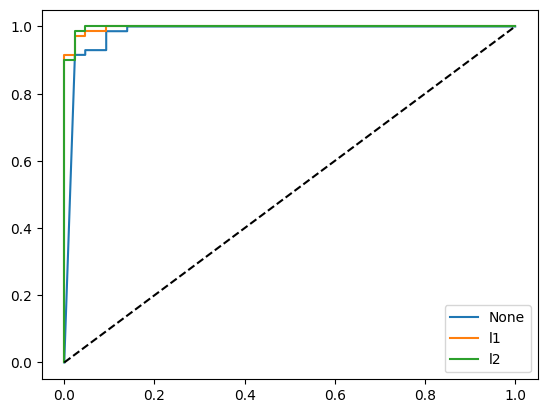

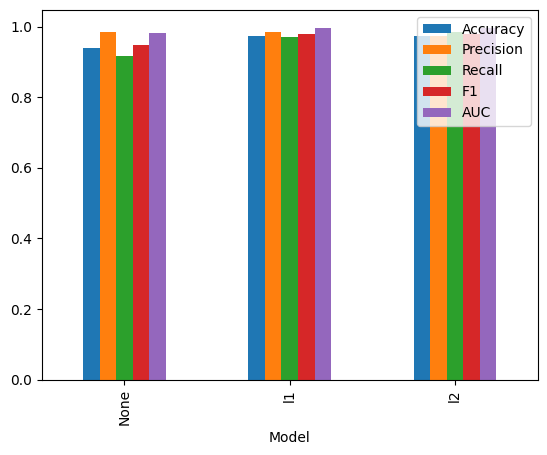

In [5]:
# Start
# Load Breast Cancer dataset
# Split features and target into train and test sets
# Standardize features
# Train Logistic Regression using MLE, L1 and L2
# Predict class labels and probabilities
# Calculate Accuracy, Precision, Recall, F1 and AUC
# Display confusion matrices and compare coefficients
# Plot ROC curves and performance comparison
# Stopimport pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

X, y = load_breast_cancer(return_X_y=True)
a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=42)

s = StandardScaler()
a = s.fit_transform(a)
b = s.transform(b)

models = [
    LogisticRegression(penalty=None, max_iter=2000),
    LogisticRegression(penalty='l1', solver='liblinear', max_iter=2000),
    LogisticRegression(penalty='l2', max_iter=2000)
]

R = []
for m in models:
    m.fit(a, c)
    v = m.predict(b)
    p = m.predict_proba(b)[:, 1]
    f, t, _ = roc_curve(d, p)
    R.append([m.penalty, accuracy_score(d, v), precision_score(d, v),
              recall_score(d, v), f1_score(d, v), auc(f, t)])
    print(confusion_matrix(d, v))
    plt.plot(f, t, label=str(m.penalty))

cols = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
print(pd.DataFrame(R, columns=cols))
print("Zero coefficients:", [sum(m.coef_[0] == 0) for m in models])

plt.plot([0, 1], [0, 1], 'k--')
plt.legend()
plt.show()

pd.DataFrame(R, columns=cols).set_index('Model').plot.bar()
plt.show()